# PAC reasoning in five minutes

This notebook calibrates the switching threshold on synthetic data and checks the resulting error,
expert call percentage (ECP) and saved token percentage (STP). To run it on real model outputs, replace the
arrays with `pac_reasoning.load_routing_data(...)` (see the README).

In [1]:
import numpy as np
from pac_reasoning import RoutingData, binary_loss, pac_calibrate, run_trials, split_indices, summarize
from pac_reasoning.plotting import plot_curves

rng = np.random.default_rng(0)
n = 1000
uncertainty = rng.beta(2, 5, n)                              # U of the non-thinking answer
nonthinking_correct = rng.random(n) > 0.4 * uncertainty       # wrong more often when uncertain
thinking_correct = rng.random(n) > 0.05
thinking_tokens = rng.integers(2000, 8000, n)
nonthinking_tokens = rng.integers(200, 800, n)

loss = binary_loss(thinking_correct, nonthinking_correct)
print(f"loss of always using the non-thinking model: {loss.mean():.4f}")

loss of always using the non-thinking model: 0.1070


## One calibration / test split

In [2]:
calib_idx, test_idx = split_indices(n, calib_ratio=0.5, seed=0)
calib = pac_calibrate(loss[calib_idx], uncertainty[calib_idx], epsilon=0.05, alpha=0.05, pi=0.5, rng=0)
routed = calib.route(uncertainty[test_idx])
print(f"threshold u_hat = {calib.threshold:.4f}")
print(f"test error = {np.mean(loss[test_idx] * ~routed):.4f} (target 0.05)")
print(f"thinking model called on {routed.mean():.1%} of the test queries")

threshold u_hat = 0.2481
test error = 0.0200 (target 0.05)
thinking model called on 53.0% of the test queries


## 100 random splits over a range of tolerances

In [3]:
data = RoutingData(losses=loss, scores=uncertainty,
                   thinking_tokens=thinking_tokens, nonthinking_tokens=nonthinking_tokens,
                   thinking_correct=thinking_correct, nonthinking_correct=nonthinking_correct)
summaries = {m: [summarize(run_trials(data, eps, n_trials=100, calib_ratio=0.5, method=m))
                 for eps in np.arange(0.02, 0.105, 0.01)]
             for m in ("pac", "naive")}
for s in summaries["pac"]:
    print(f"eps={s['epsilon']:.2f}  error {s['error']:.4f} ± {s['error_std']:.4f}  "
          f"ECP {s['ecp']:5.1f}%  STP {s['stp']:5.1f}%")

eps=0.02  error 0.0117 ± 0.0079  ECP  69.1%  STP  20.5%
eps=0.03  error 0.0188 ± 0.0112  ECP  60.9%  STP  28.4%
eps=0.04  error 0.0280 ± 0.0137  ECP  53.9%  STP  35.4%
eps=0.05  error 0.0388 ± 0.0168  ECP  44.6%  STP  44.9%
eps=0.06  error 0.0473 ± 0.0188  ECP  37.7%  STP  52.0%
eps=0.07  error 0.0554 ± 0.0197  ECP  30.5%  STP  59.3%
eps=0.08  error 0.0645 ± 0.0213  ECP  23.7%  STP  66.2%
eps=0.09  error 0.0740 ± 0.0210  ECP  16.5%  STP  73.4%
eps=0.10  error 0.0809 ± 0.0204  ECP  12.0%  STP  78.0%


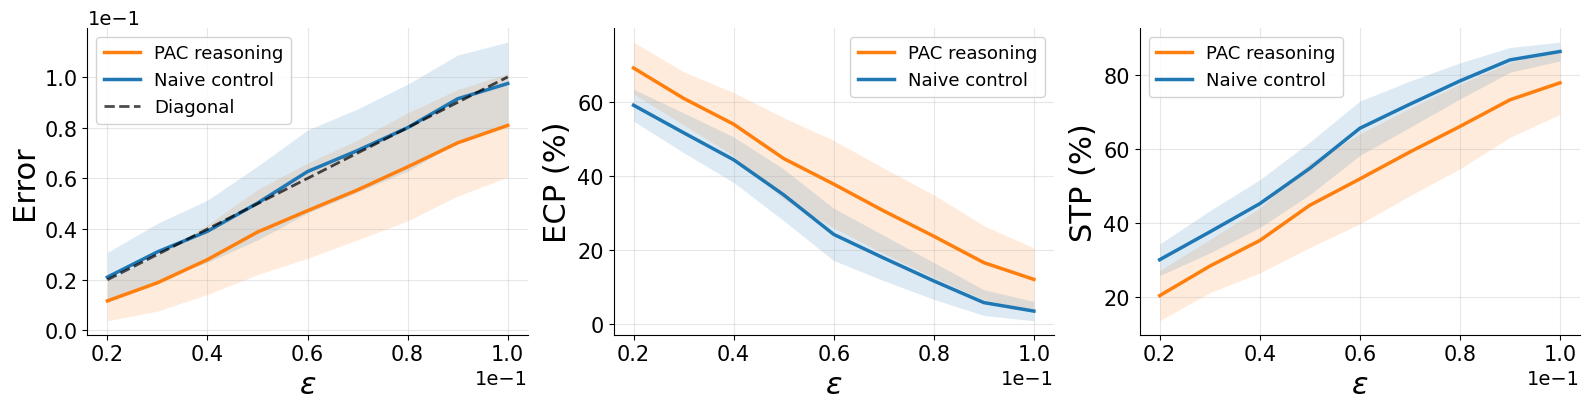

In [4]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
curves = {"PAC reasoning": summaries["pac"], "Naive control": summaries["naive"]}
for ax, metric in zip(axes, ("error", "ecp", "stp")):
    plot_curves(curves, metric, ax=ax)
fig.tight_layout()